# Khoi: MNIST single-pass experiment and CIFAR comparison

**Completed run:** `mnist_seed42_complete`. This notebook reads saved results; it does not train, download datasets, or use the official test set.

The assignment asks for **SmallResNet on MNIST versus SmallResNet on CIFAR**. The reproducible online CIFAR SmallResNet CSV and settings are not published in the inspected repository. That comparison is therefore pending. The available CIFAR GaussianNB results are shown separately as context: they change both dataset and model and cannot isolate a dataset effect.

Sources: `docs/10-19_assignment.md`, `docs/mnist_experiment.md`, the archived MNIST run below, and `results/gaussiannb_results.csv`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/mnist.yaml").is_file())
RUN = ROOT / "results/mnist_seed42_complete"
mnist = pd.read_csv(RUN / "results.csv")
cifar = pd.read_csv(ROOT / "results/gaussiannb_results.csv")
metadata = json.loads((RUN / "run.json").read_text())
membership = json.loads((RUN / "membership.json").read_text())
final = mnist.iloc[-1]
assert mnist.run_id.nunique() == 1
assert set(mnist.eval_split) == {"validation"}
assert mnist.examples_processed.is_monotonic_increasing
assert final.examples_processed == 54000 and final.updates == 1688
assert metadata["config"]["passes"] == 1 and not metadata["config"]["replay"]
assert metadata["examples_processed"] == 54000 and metadata["updates"] == 1688
assert mnist.accuracy.between(0, 1).all()
print("Completed saved run verified: 54,000 examples; 1,688 updates; validation metrics.")

Completed saved run verified: 54,000 examples; 1,688 updates; validation metrics.


## Split and run evidence

IDs below are original MNIST training-source rows. Validation belongs to that source split but is excluded from optimization. This metadata section confirms separation and coverage. A separate checkpoint re-evaluation is reported below. Automated tests separately check loader behavior, metric calculation, and evaluation state preservation.

In [2]:
train = membership["train_stream_rows"]
validation = membership["validation_rows"]
assert membership["source_split"] == "train"
assert len(train) == len(set(train)) == 54000
assert len(validation) == len(set(validation)) == 6000
assert not set(train) & set(validation)
assert set(train) | set(validation) == set(range(60000))
assert 54000 // 32 == 1687 and 54000 % 32 == 16
print("Train: 54,000 | Validation: 6,000 | Overlap: 0 | Source coverage: 60,000")
print("Batches: 1,687 full + final 16 = 1,688 updates")
print("Example training ID:", f"train:{train[0]}")
print("Example validation ID:", f"train:{validation[0]}")
display(pd.DataFrame([{
    "Validation accuracy (%)": 100 * final.accuracy,
    "Macro precision (%)": 100 * final.precision,
    "Macro recall (%)": 100 * final.recall,
    "Macro F1 (%)": 100 * final.f1,
    "Training compute (minutes)": metadata["training_seconds"] / 60,
    "Run wall time (minutes)": metadata["total_wall_seconds"] / 60,
    "Device": metadata["device"],
}]).round(3))
print("Hardware:", metadata["processor"])
print("Package versions:", metadata["packages"])
print("Run command:", " ".join(metadata["command"]))

Train: 54,000 | Validation: 6,000 | Overlap: 0 | Source coverage: 60,000
Batches: 1,687 full + final 16 = 1,688 updates
Example training ID: train:12827
Example validation ID: train:37542


,Validation accuracy (%),Macro precision (%),Macro recall (%),Macro F1 (%),Training compute (minutes),Run wall time (minutes),Device
0,99.083,99.103,99.072,99.085,48.262,90.513,cpu


Hardware: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel
Package versions: {'torch': '2.14.1', 'torchvision': '0.29.1', 'numpy': '2.5.2', 'PyYAML': '6.0.3', 'matplotlib': '3.11.2'}
Run command: python -m src.train_online --config configs/mnist.yaml --output data/processed/mnist_seed42_complete --download


## MNIST learning curve

All ten digits are mixed. Images remain 1 x 28 x 28 with `ToTensor()` scaling to [0, 1] and identity model normalization. SmallResNet uses one input channel and ten outputs; Adam uses learning rate 0.001, batch size 32, seeds 42, one pass, no replay or pretraining.

Accuracy fluctuates at intermediate checkpoints. The reported result is the **final** checkpoint, not a selected best score. Macro metrics give each class equal weight.

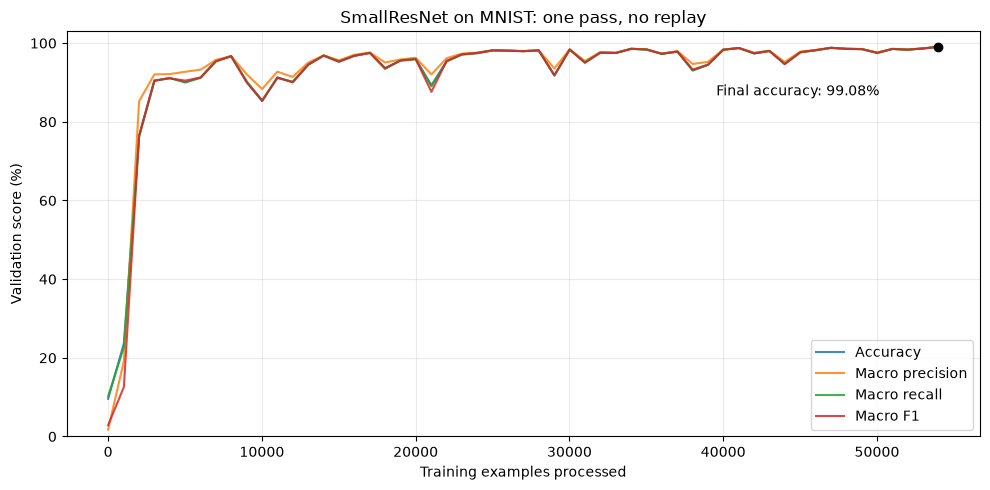

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for metric, label in [("accuracy", "Accuracy"), ("precision", "Macro precision"),
                       ("recall", "Macro recall"), ("f1", "Macro F1")]:
    ax.plot(mnist.examples_processed, 100 * mnist[metric], label=label, alpha=0.85)
ax.scatter([final.examples_processed], [100 * final.accuracy], color="black", zorder=5)
ax.annotate(f"Final accuracy: {100 * final.accuracy:.2f}%",
            (final.examples_processed, 100 * final.accuracy),
            xytext=(-160, -35), textcoords="offset points")
ax.set(xlabel="Training examples processed", ylabel="Validation score (%)",
       ylim=(0, 103), title="SmallResNet on MNIST: one pass, no replay")
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Available CIFAR context - different dataset AND different model

These are separate experiments, not a controlled model or dataset comparison. MNIST has 10 digit classes and 54,000 training examples; the CIFAR run has 20 object classes and 9,000 training examples. Different validation populations and unknown GaussianNB hardware/timing boundaries prevent direct speed or quality rankings. Equal percentages of a pass still represent different amounts of data.

GaussianNB's first reported point is after 1,024 examples; no untrained prediction is invented. The assignment's actual same-model CIFAR comparison remains unavailable.

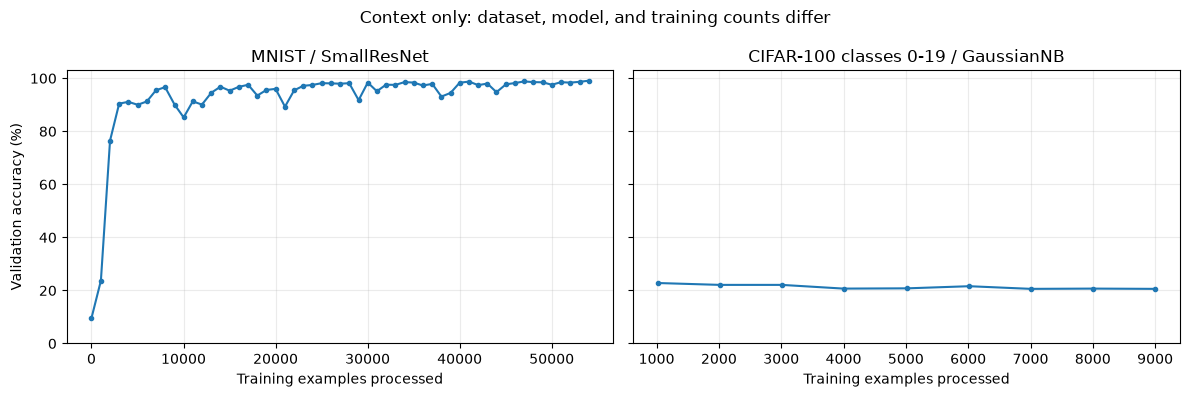

,Experiment,Train,Validation,Classes,Updates,Final accuracy (%),Timing reported (s),Comparison status
0,MNIST / SmallResNet,54000,6000,10,1688.0,99.083,2895.75,Completed; local CPU metadata saved
1,CIFAR / GaussianNB,9000,1000,20,282.0,20.6,0.788,Context only; timing scope/hardware unverified
2,CIFAR / SmallResNet,9000,1000,20,Unavailable,Unavailable,Unavailable,Original online CSV/config unpublished; counts...


In [4]:
cf = cifar.sort_values("examples_processed")
assert cf.run_id.nunique() == 1 and set(cf.eval_split) == {"validation"}
assert cf.accuracy.between(0, 1).all()
cf_final = cf.iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, frame, title in [(axes[0], mnist, "MNIST / SmallResNet"),
                          (axes[1], cf, "CIFAR-100 classes 0-19 / GaussianNB")]:
    ax.plot(frame.examples_processed, 100 * frame.accuracy, marker=".")
    ax.set(title=title, xlabel="Training examples processed", ylim=(0, 103))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Validation accuracy (%)")
fig.suptitle("Context only: dataset, model, and training counts differ")
fig.tight_layout()
plt.show()

display(pd.DataFrame([
 {"Experiment": "MNIST / SmallResNet", "Train": 54000, "Validation": 6000,
  "Classes": 10, "Updates": int(final.updates), "Final accuracy (%)": 100 * final.accuracy,
  "Timing reported (s)": final.training_seconds, "Comparison status": "Completed; local CPU metadata saved"},
 {"Experiment": "CIFAR / GaussianNB", "Train": 9000, "Validation": 1000,
  "Classes": 20, "Updates": int(cf_final.updates), "Final accuracy (%)": 100 * cf_final.accuracy,
  "Timing reported (s)": cf_final.training_seconds, "Comparison status": "Context only; timing scope/hardware unverified"},
 {"Experiment": "CIFAR / SmallResNet", "Train": 9000, "Validation": 1000,
  "Classes": 20, "Updates": None, "Final accuracy (%)": None,
  "Timing reported (s)": None, "Comparison status": "Original online CSV/config unpublished; counts intended"},
]).round(3).fillna("Unavailable"))

## Findings and assignment status

- MNIST final validation accuracy is **99.0833%**, with macro F1 **0.990846**, after one pass and 1,688 optimizer updates. It is validation accuracy from one seed, not official test accuracy or a repeated-seed estimate.
- On 6,000 validation images, the saved accuracy corresponds to **55 incorrect predictions**. Checkpoint inference has now been independently rerun; the audit and error images appear below.
- Training compute was about **48.26 minutes**; run wall time was about **90.51 minutes** on CPU. Wall time includes validation and loading during the run, but not initial dataset setup before the timer. These are different timing scopes.
- The available CIFAR GaussianNB run ends at **20.6%**. It does not show how SmallResNet would perform on CIFAR, nor establish that one method is better: model, dataset, counts and preprocessing differ.
- Still needed for the requested dataset comparison: Nguyen's original online SmallResNet CIFAR CSV, configuration/preprocessing, and hardware/timing. The historical task-incremental notebook and an informal 39.5% report are not substituted for those artifacts.
- Shared CIFAR trainer parity remains unverified; the standalone MNIST settings are explicitly provisional. No additional model training is performed here.

## Reproduction and test evidence

From the repository root:

```powershell
python -m pip install -r requirements.txt
python -m pytest -v
python -m src.train_online --config configs/mnist.yaml --output data/processed/mnist_seed42_complete --download
```

The output folder must be new for a new experiment; the original completed run must be preserved. The user-supplied terminal log reports **23 passed, 2 warnings in 319.83 seconds**; the warning messages were not included in that excerpt. This notebook is analysis of saved evidence, not a rerun of that test suite.

To run this notebook, install `nbformat nbclient ipykernel` and select the Python environment with the project dependencies, then **Run All**. It runs from the root or `notebooks/` using committed CSV/JSON metadata; local dataset images and model weights are not needed. Dataset downloads and `model.pt` stay excluded from Git.

## Independent checkpoint audit

`src.audit_mnist` reloads the original saved checkpoint on CPU and evaluates the saved 6,000 validation source rows directly. It checks the configured loader membership agrees, no training/validation overlap exists, model state stays unchanged, and all four metrics match the final saved CSV within 1e-12. Accuracy is also counted directly, and macro metrics are cross-checked with a separate per-class calculation. No training, downloads or official test evaluation are performed.

The confusion matrix and first 20 mistakes are diagnostic evidence; they do not establish performance on unseen datasets or across random seeds. Predictions and checkpoint SHA-256 are retained for auditing.

Reproduce locally (requires original local checkpoint; use a new output folder):

```powershell
python -m src.audit_mnist --run data/processed/mnist_seed42_complete --output data/processed/mnist_checkpoint_audit_new
```

Fresh regression run: `python -m pytest -v --tb=short` with offline Hugging Face mode and pytest temp root set to `.pytest_cache`: **23 passed in 48.87s**, no warnings reported. The original run's two warning messages were not available, so their cause is not inferred.


Reloaded model reproduced final metrics: {'accuracy': 0.9908333333333333, 'precision': 0.9910304361075098, 'recall': 0.9907229931173044, 'f1': 0.9908458768460889}
Correct: 5945 / 6000; mistakes: 55; no overlap; no model changes
Checkpoint SHA-256: 824c01b272ed7b3d8018c7640ef3b7e456798c640abf42c3a19caa728a19c113


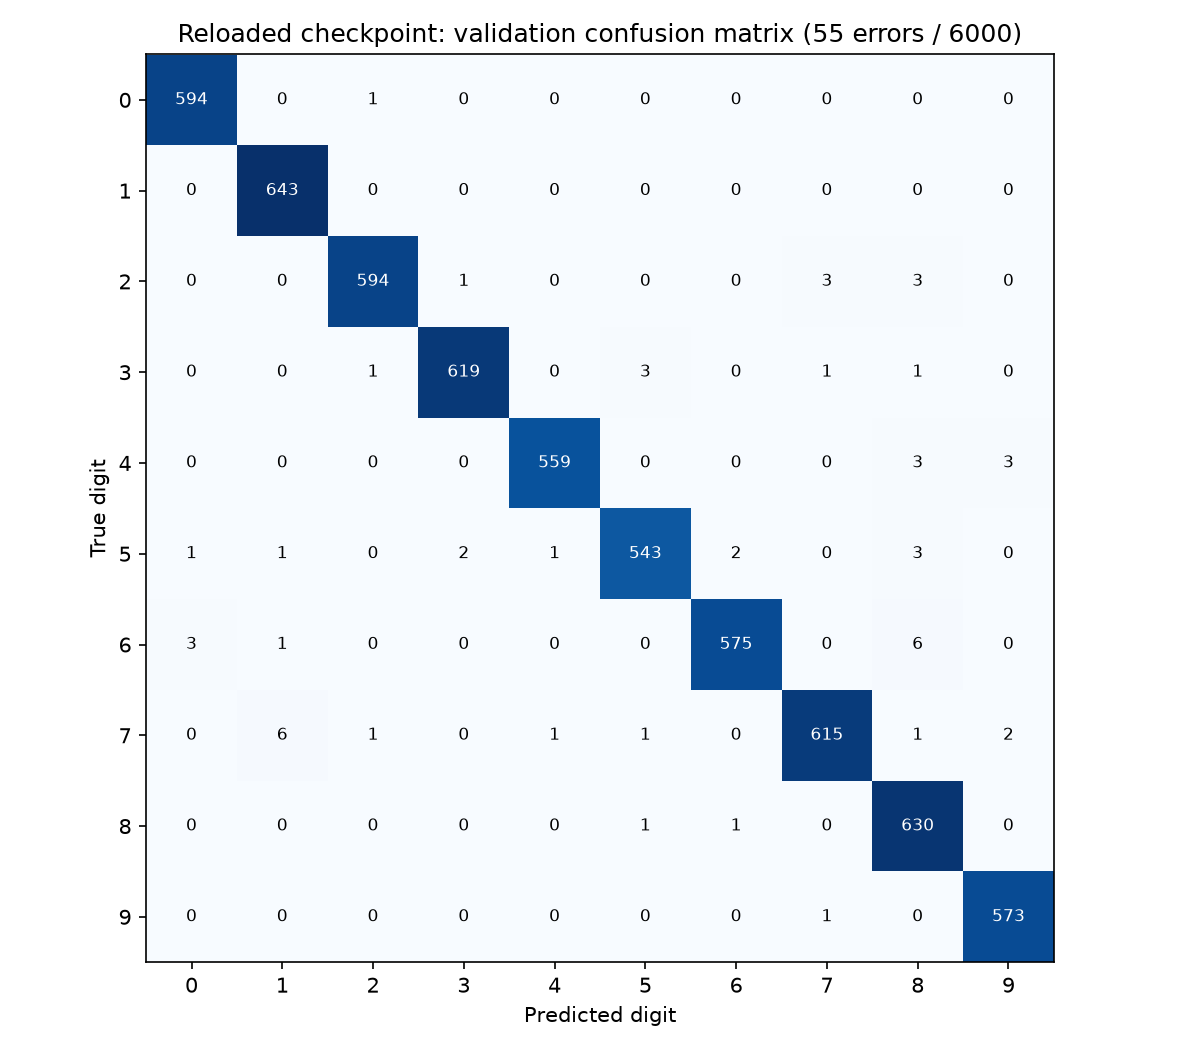

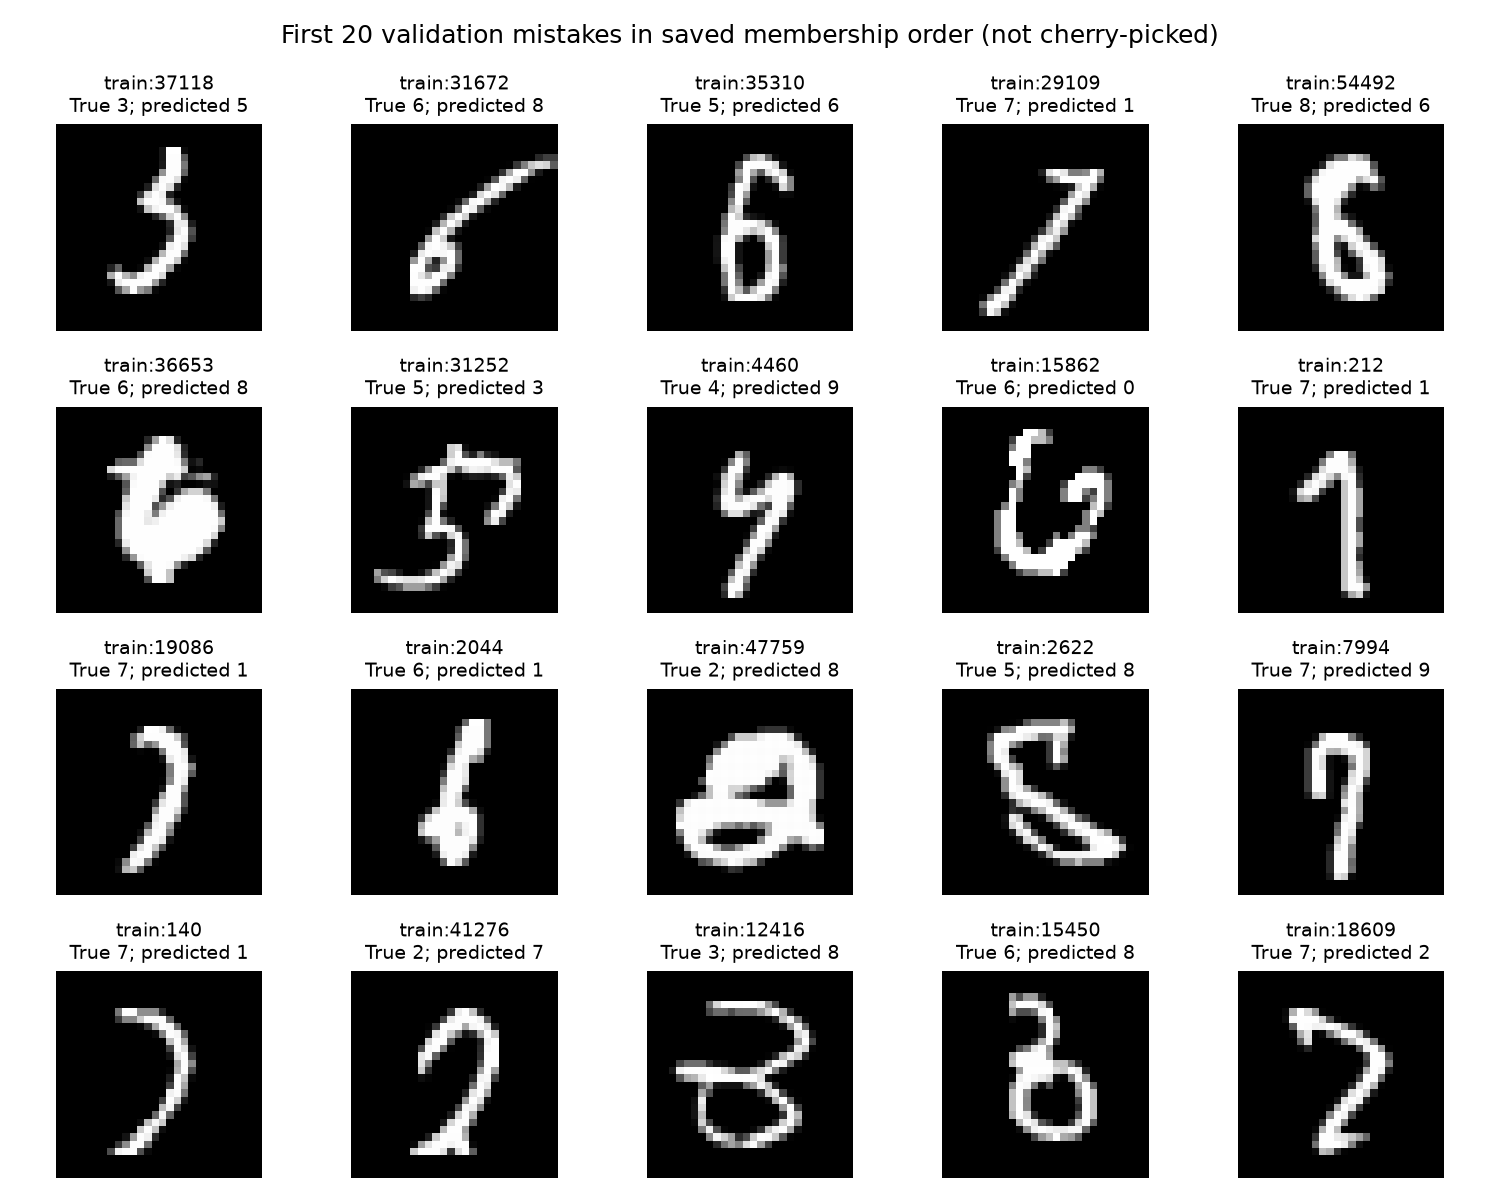

In [5]:
from IPython.display import Image
AUDIT = RUN / "audit"
audit = json.loads((AUDIT / "audit.json").read_text())
assert audit["validation_examples"] == 6000
assert audit["mistakes"] == 55 and audit["correct"] == 5945
assert audit["train_validation_overlap"] == 0
assert audit["model_state_unchanged"] and audit["loader_membership_matches"]
assert not audit["official_test_set_used"]
for name, value in audit["metrics"].items():
    assert abs(value - float(final[name])) < 1e-12
print("Reloaded model reproduced final metrics:", audit["metrics"])
print("Correct: 5945 / 6000; mistakes: 55; no overlap; no model changes")
print("Checkpoint SHA-256:", audit["checkpoint_sha256"])
display(Image(filename=str(AUDIT / "confusion_matrix.png")))
display(Image(filename=str(AUDIT / "misclassified_examples.png")))